<h1> Problem Set 4 - CBE </h1>
<h6><i> Namrata Pradeep </i></h6>
<h3><b> Problem 1 (4.19)
</b></h3>
<h6> Recall the optimization (minimization) framework that we used to solve the non-linear simul-
taneous equations in Example 4.7-3. We made use of the scipy.optimize.minimize function. This is
covered in the Python tutorial notebook on Solving Simultaneous Equations. Use the same approach
to solve the system of linear simultaneous equations in 4.19.</h6>

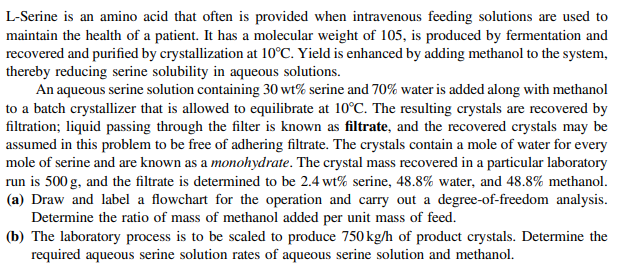

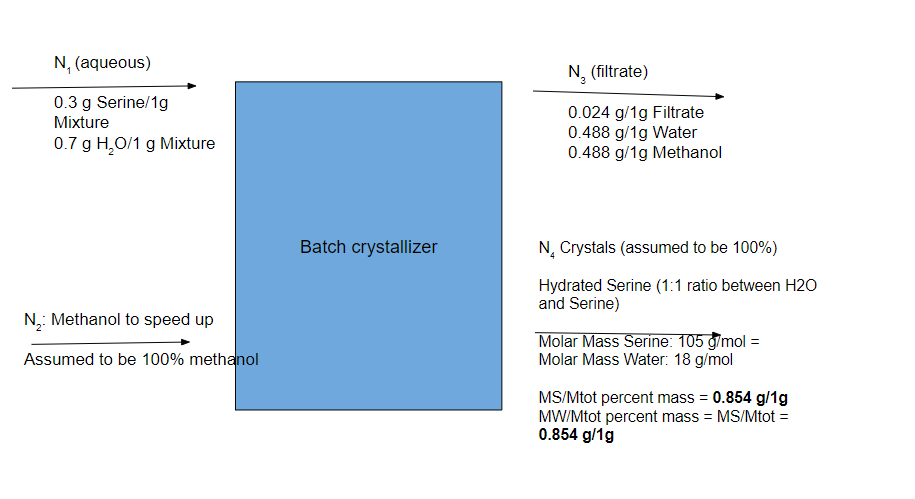

$Serine Mass Balance:
0.30n_1 + 0n_2 - 0.024 n_3 =  0.854 * 500g $    (this side is a constant going into our B matrix)

$Water:
0.70n_1 + 0n_2 - 0.488n_3  =  0.146 * 500g $    (a constant going into our B matrix)

$Methanol:
0n_1 + 1n_2 - 0.488n_3 = 0 $

Knowing:
$n_4 = 500g$




In [ ]:
import numpy as np

from scipy import optimize

def MyFunction(parameters):
    n1,n2,n3 = parameters
    eqn1 =(0.3*n1-0.024*n3 -(.500*0.854))**2
    eqn2 =(0.7*n1-0.488*n3 - (.500*0.146))**2
    eqn3 = (n2-0.488*n3 )**2
    return eqn1 + eqn2 + eqn3

initial_guess = [1000,1000,1000]
bnds = ((0,4000),(0,4000),(0,4000))
result = optimize.minimize(MyFunction, initial_guess, bounds=bnds, tol=1E-12)
print(result.x)
fsol1 = result.x[0]
fsol2 = result.x[1]
fsol3 = result.x[2]

print(f'The solved value for n1 is: {fsol1:.3f} kg of aqueous serine ')
print(f'The solved value for n2 is: {fsol2:.3f} kg of methanol')
print(f'The solved value for n3 is: {fsol3:.3f} kg of filtrate')

#Linalg approach
print("-----------------------")
A = np.array([[0.30,0,-0.024],[0.70,0,-0.488],[0,1,-0.488]])
B = np.array([0.854*0.5,0.146*0.500,0])
solution = np.linalg.solve(A,B)
solution_alternative_method = np.linalg.inv(A).dot(B)
sol1 = float(solution[0])
sol2 = float(solution[1])
sol3 = float(solution[2])


print(f'The solved value for n1 is: {sol1:.3f} kg of aqueous serine ')
print(f'The solved value for n2 is: {sol2:.3f} kg of methanol')
print(f'The solved value for n3 is: {sol3:.3f} kg of filtrate')

print('The solved values using the explicit matrix inversion and dot product are the same: ', solution_alternative_method)

print(f'Mass of Methanol Per Unit Mass of Feed:{sol2:.3f}kg/{sol2+sol1:.3f}kg = {sol2/(sol2+sol1):.3f} kg/1kg feed')

part b w/ 750 kg/h

$Serine Mass Balance:
0.30n_1 + 0n_2 - 0.024 n_3 =  0.853 * 750 \frac{kg}{h} $

$Water:
0.70n_1 + 0n_2 - 0.488n_3  =  0.146 * 750 \frac{kg}{h} $

$Methanol:
0n_1 + 1n_2 - 0.488n_3 = 0 $

Knowing:
$n_4 = 750 kg/h$




In [ ]:
from scipy import optimize

def MyFunction(parameters):
    n1,n2,n3 = parameters
    eqn1 =(0.3*n1-0.024*n3 -640.275)**2
    eqn2 =(0.7*n1-0.488*n3 - 109.725)**2
    eqn3 = (n2-0.488*n3 )**2
    return eqn1 + eqn2 + eqn3

initial_guess = [1000,1000,1000]
bnds = ((0,4000),(0,4000),(0,4000))
result = optimize.minimize(MyFunction, initial_guess, bounds=bnds, tol=1E-12)
print(result.x)
fsol1 = result.x[0]
fsol2 = result.x[1]
fsol3 = result.x[2]




print(f'The solved value for n1 is: {fsol1:.3f} kg/h of aqueous serine ')
print(f'The solved value for n2 is: {fsol2:.3f} kg/h of methanol')
print(f'The solved value for n3 is: {fsol3:.3f} kg/h of filtrate')

print('The solved values using the explicit matrix inversion and dot product are the same: ', solution_alternative_method)



<h3><b> Problem 2 </b></h3>
<h6>Chemical reaction engineering typically involves answering the following fundamental questions.
*  What will be the equilibrium composition of the reaction mixture?
*  How long will the system take to reach a specific state, short of equilibrium?
What subject/discipline/field within chemical engineering concerns itself with the first question? What subject/discipline/field within chemical
engineering concerns itself with the second question? </h6>
Answer:
thermodynamics is all about the equilibrium composition of the reaction mixture.
kinetics is all about how long it will take a reaction to reach a certain state.


<h3><b> Problem 3 </b></h3>
<h6>Solve for roots </h6>
 x^3 − 2x^2 − 29x = −30 (1)

2x^3 − 27x^2 + 52x = −33 (2)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
coef1 = np.array([1,-2,-29,30])
ans1 = np.roots(coef1)
print(f'roots for the first eq{ans1}')

coef2 = np.array([2,-27, 52, 33])
ans2 = np.roots(coef2)
print(f'roots for the second eq{ans2}')


<h3><b> Problem 4.21 </b></h3>
<h6> a). Plot the analyzer calibration data on logarithmic axes and determine an expression for xP(R) </h6>

The basic linear function is  
0.001426 x - 0.07517
the A-value is 0.00014491193299120798 and the B-value is 1.3645457425169747
This is the equation of the line of best fit in exponential form:
x_P =  0.000145 * R ^ 1.3645


Text(0.5, 1.0, 'Mass Percent of Product vs. Reactor Reading')

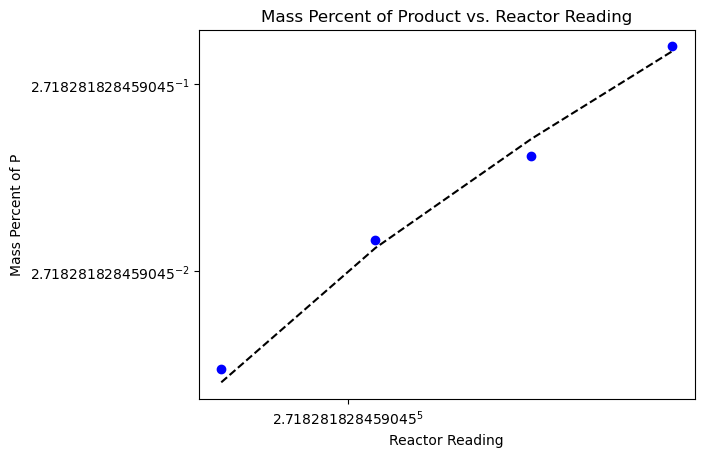

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

xp = np.array([0.08, 0.16, 0.25, 0.45])
R = np.array([105,160,245,360])


# start off by doing a degree 1 fit following y = mx+b
coef = np.polyfit(R,xp,1)
# we have some coefficients for m & b that we can now plot
fit = np.poly1d(coef)
plt.plot(R,xp,"bo", R, fit(R), "--k") # the first two arguments are our numerical data that are being scattered, the next two are our approximate linear fit

print(f"The basic linear function is {fit}")
plt.xscale("log", base = np.e)
plt.yscale("log", base = np.e)


#can we get coefficients that better represent the exponential nature?
coef_log = np.polyfit(np.log(R), np.log(xp), 1)

a = np.exp(coef_log[1])
b = coef_log[0]
print(f"the A-value is {a} and the B-value is {b}")

# # To put into the form y = a*x^b, b will equal exp() of the value determined with polyfit

print ('This is the equation of the line of best fit in exponential form:')
print('x_P = ', "{:.6f}".format(a),'*','R','^', "{:.4f}".format(b))


plt.xlabel("Reactor Reading")
plt.ylabel("Mass Percent of P")
plt.title("Mass Percent of Product vs. Reactor Reading")

<h6>b). The data sheet for one run is shown below:
Batch #: 23601 Date: 10/4

Mass charged to reactor: 2253 kg

Mass of purified product: 1239 kg

Reactor effluent analysis: R = 388

Final product analysis: R = 583

Waste stream analysis: R = 140

Calculate the mass fractions of P in all three streams. Then calculate the percentage yield of the
purification process, <h6>


In [ ]:
Ra = 388
xp1 = a*Ra**b
print(f"The percent of P in the Reactor Effluent is {xp1*100:.3f}% and the mass is {2253*xp1:.3f} kg")
Rb = 583
xp2 = a*Rb**b
print(f"The percent of P in the Final product is {xp2*100:.3f}% and the mass of P is {1239*xp2:.3f} kg")



kgfin = 1239 * xp2
print(f"kilograms in final product =  1239 kg * xP of the final product = {kgfin:.3f} kg")
kgeff = (2253) * xp1
print(f"kilograms in reactor effluent =  (charged-product)* xP of the effluent = {kgeff:.3f} kg")

yld = (kgfin/kgeff)
print(f"Yield is {yld*100:.3f}%")



The percent of P in the Reactor Effluent is 49.395% and the mass is 1112.871 kg
The percent of P in the Final product is 86.096% and the mass of P is 1066.735 kg
kilograms in final product =  1239 kg * xP of the final product = 1066.735 kg
kilograms in reactor effluent =  (charged-product)* xP of the effluent = 1112.871 kg
Yield is 95.854%


<h6>c). You are the engineer in charge of the process. You review the given run sheet and the calculations
of Part (b), perform additional balance calculations, and realize that all of the recorded run data
cannot possibly be correct. State how you know, itemize possible causes of the problem, state
which cause is most likely, and suggest a step to correct it. </h6>

One major source of error is that this was an exttrapolation beyond analyzer calibrain data. We put in reactor values of 388 and 583, when we had only fit it to a highest reading of 360. Therefore we don't know how reliable these equations are at giving us an accurate percent mass at higher reactor readings.

Well the yield is really high, which is good since we want P. Mass of the P species in the waste stream and final product should sum to the mass of the p in the reactor effluent, since the reaction is DONE & no new P should be made at this phase. We are trying to get a high quality P stream.

Instead, P at the end of the reaction is 1063.187 kg, while we started with 1077.258 kg in the effluent of the last step.

Sources of error could be P getting stuck in the tank & one way we would correct this is by altering the material in which the purification process takes place by getting something that is less cohesive to the substance P. We could also just get a better purifier or add something that improves dissolution.



<h3><b>Problem 4.54 </b></h3>

The respiratory process involves hemoglobin (Hgb), an iron-containing compound found in red blood
cells. In the process, carbon dioxide diffuses from tissue cells as molecular CO2, while O2 simultaneously
enters the tissue cells. A significant fraction of the CO2 leaving the tissue cells enters red blood cells and
reacts with hemoglobin; the CO2 that does not enter the red blood cells ( 1 in the figure below) remains
dissolved in the blood and is transported to the lungs. Some of the CO2 entering the red blood cells reacts
with hemoglobin to form a compound (Hgb⋅CO2; 2 in the figure). When the red blood cells reach the
lungs, the Hgb⋅CO2 dissociates, releasing free CO2. Meanwhile, the CO2 that enters the red blood cells
but does not react with hemoglobin combines with water to form carbonic acid, H2CO3 , which then dissociates into hydrogen ions and bicarbonate ions ( 3 in the figure). The bicarbonate ions diffuse out of the cells ( 4 in the figure), and the ions are transported to the lungs via the bloodstream.


For adult humans, every deciliter of blood transports a total of 1.6 x 10^-4 mol of carbon dioxide in
its various forms (dissolved CO2, Hgb x CO2, and bicarbonate ions) from tissues to the lungs under
normal, resting conditions. Of the total CO2, 1.1x10^-4 mol are transported as bicarbonate ions. In a
typical resting adult human, the heart pumps approximately 5 liters of blood per minute. You have been
asked to determine how many moles of CO2 are dissolved in blood and how many moles of HgbxCO2
are transported to the lungs during an hour’s worth of breathing

$ CO_2 +  H_2O --> H_2CO_3$

$ H_2CO_3 --> H^+ + HCO_3- $ #creation of bicarbonate, first type of CO2

$y  CO_2 + Hgb ->  HgbCO2 $ simple reaction to create type #2 of CO2

in additional some of the CO2 remains in its dissolved state

$ (1-y    ) CO_2 + H_2O -> H^+ + HCO_3^+ $



$ \mathrm1.6*10^{-4}= n_1 =  BIC + Dissolved +  HgbCO2 $

$ \mathrm1.6*10^{-4} =  xyn_1 + (1-x)n_1 +  x(1-y)n_1$

$ BIC: \mathrm1.1*10^{-4} =  xyn_1  $

$ Dissolved :  (1-x)n_1 $

$ Hgb:  x(1-y)n_1$

$ (1) \mathrm1.6*10^{-4} =  xyn_1 + (1-x)n_1 +  x(1-y)n_1$

1 equations & 2 unknowns (x,y) --> underspecified.

b). can we solve it?

but don't be tricked: we actually only have 1 equations

and this is not going to be solved. We need at least x or y to be given to us.

We are now going assumed a value for x to be 0.8 (literary meaning: 80% of the plasma CO2 goes into Red Blood Cells).
Going back to the equation:

$ BIC: \mathrm1.1*10^{-4} =  xyn_1  $

when x = 0.8, y will be 0.859!

c). Lots of hydrogen atoms coming from the carbonic acid raises the pH of the tissues. This is called acidosis, and can lead to cell death by causing dangerous cascades of signalling. It can lead to neurosis and disorientation as other common symptoms






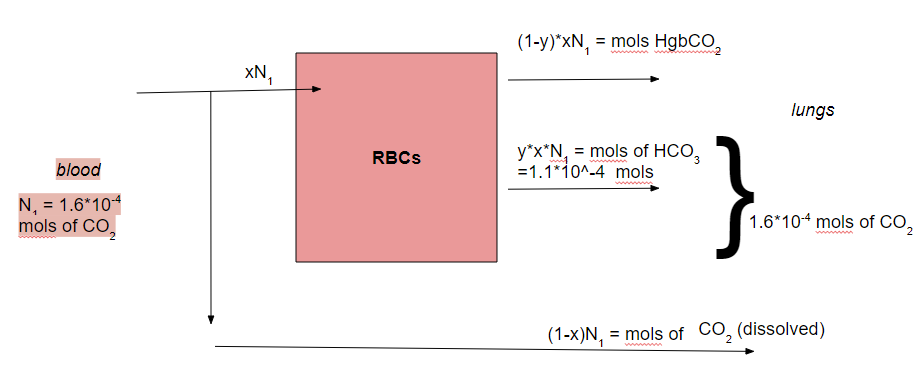

In [ ]:
#moles of CO2 transported within 1 hour --> now we are dealing with rates.
rate = 5 #L/min
conc = 1.6*10**-4 # moles of CO2/dL
conc = conc * 10 #moles per Liter

lpermin = rate *60 #liters per hour
moles = conc *lpermin #moles per hour

dissolved = moles*0.2  #(n*(1-x))

hgb = moles * 0.8*(1-0.859)   #(n*x*(1-y))

print(f"The number of moles transported through dissolved CO2 per hour {dissolved:.3f} moles")
print(f"The number of moles of HgB*CO2 per hour  {hgb:.3f} moles")

